# Step 1 — An image is just a grid of numbers

Before any machine learning, you need to be comfortable with one idea:
**a photo, to a computer, is a big table of numbers.** Nothing else.

Run each cell with **Shift + Enter**.

If something breaks, that's fine — tell me what the error says.

In [3]:
# numpy = the library for working with grids of numbers
# matplotlib = the library for drawing pictures
import numpy as np
import matplotlib.pyplot as plt

# Load our images. mmap_mode='r' means "don't load all 800 MB into memory,
# just read bits of the file when I ask for them".
images = np.load('../data/processed/X_train.npy', mmap_mode='r')
labels = np.load('../data/processed/y_train.npy')

print('how many images do we have?', len(images))
print('how many labels do we have?', len(labels))


how many images do we have? 5321
how many labels do we have? 5321


You should see **5321** twice.

That's our training set: 5,321 photos, and 5,321 labels saying whether each
one shows damage.

Now let's pull out a single photo and look at what it actually *is*.

In [4]:
# Python counts from 0, so image number 0 is the first one.
photo = images[0]

print('shape :', photo.shape)
print('dtype :', photo.dtype)
print('smallest number in it:', photo.min())
print('biggest number in it :', photo.max())

shape : (224, 224, 3)
dtype : uint8
smallest number in it: 9
biggest number in it : 255


Read that output carefully, because it tells you everything:

- **shape `(224, 224, 3)`** — 224 rows, 224 columns, and 3 numbers per
  position. Those 3 are how much **R**ed, **G**reen and **B**lue.
- **dtype `uint8`** — "unsigned 8-bit integer", i.e. a whole number from
  0 to 255. That's the normal range for an image: 0 = none of that colour,
  255 = as much as possible.

So this photo is **224 × 224 × 3 = 150,528 numbers**. That's it. That's the
whole picture.

Let's prove it by looking at a few of them.

In [6]:
# One single pixel: row 100, column 100
print('the pixel at row 100, column 100 is:', photo[100, 100])
print('   its red value  :', photo[100, 100, 0])
print('   its green value:', photo[100, 100, 1])
print('   its blue value :', photo[100, 100, 2])

# A tiny 4x4 patch, red channel only, so you can see the actual grid
print()
print('a 4x4 patch of red values:')
print(photo[100:104, 100:104, 0])

the pixel at row 100, column 100 is: [198 133  93]
   its red value  : 198
   its green value: 133
   its blue value : 93

a 4x4 patch of red values:
[[198 209 211 205]
 [199 204 202 196]
 [203 204 201 197]
 [195 201 204 204]]


Those numbers **are** the image. Now let's draw them.

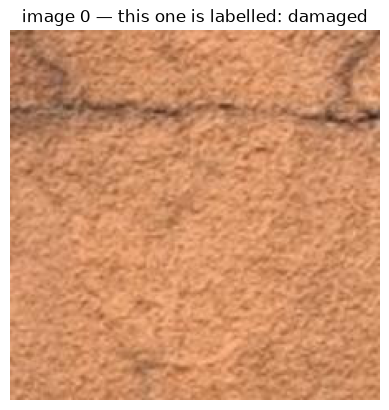

In [25]:
names = ['undamaged', 'damaged']

plt.imshow(photo)
plt.title(f'image 0 — this one is labelled: {names[labels[0]]}')
plt.axis('off')
plt.show()

---

## Your turn

Play with the cell below. Things to try:

1. Change `n` to a different number (anything from 0 to 5320) and re-run.
2. Find an image where you **disagree** with the label. They exist.
3. Try `n = 99999` and see what error you get. Errors are information.

Tell me what you find.

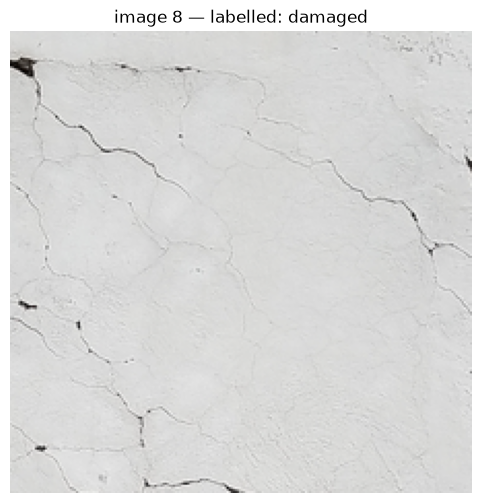

In [30]:
n =  8     # <-- change this number and press Shift+Enter

plt.figure(figsize=(6, 6))
plt.imshow(images[n])
plt.title(f'image {n} — labelled: {names[labels[n]]}')
plt.axis('off')
plt.show()

---
# Step 2 — Teaching a computer to guess

We have 5,321 photos and 5,321 labels. The goal: a program that looks at a
photo it has never seen and says *damaged* or *undamaged*.

Before building anything clever, we need to know **what score is worth
nothing**. Otherwise we can't tell a good model from a useless one.


## The dumbest possible model

Here is a 'model' that does no learning at all. It ignores the photo
completely and always shouts the same answer.

If 54% of images are undamaged, then always saying *undamaged* is right 54%
of the time. **Any real model must beat that**, or it has learned nothing.


In [ ]:
import numpy as np

y_val = np.load('../data/processed/y_val.npy')

always_undamaged = (y_val == 0).mean()
always_damaged   = (y_val == 1).mean()

print(f'always saying "undamaged": {always_undamaged:.1%} correct')
print(f'always saying "damaged"  : {always_damaged:.1%} correct')
print()
print(f'So our baseline to beat is {max(always_undamaged, always_damaged):.1%}')


## How do you feed a photo to a model?

Most classic models don't understand grids. They want one long list of
numbers per example - a *row*.

So we **flatten**: take the 224 x 224 x 3 grid and lay all its numbers out
in a single line.


In [ ]:
images = np.load('../data/processed/X_train.npy', mmap_mode='r')

one = np.asarray(images[0])
print('before flattening:', one.shape)

flat = one.reshape(-1)        # -1 means 'work out the length yourself'
print('after flattening :', flat.shape)
print()
print('224 * 224 * 3 =', 224*224*3)
print('first 10 numbers:', flat[:10])


## Now notice something uncomfortable

Each photo is **150,528 numbers**. We have **5,321 photos**.

The model has roughly **28 times more knobs to tune than examples to learn
from**.

Think about what that lets it do. Instead of learning *what damage looks
like*, it can simply memorise all 5,321 photos.

### Predict before you run

The next cell trains a real model (logistic regression) on 800 photos, then
scores it two ways:

- on the **same 800 photos it learned from**
- on **592 photos it has never seen**

Write down your guesses for both numbers before running it. Remember the
baseline is about 53%.


## Wait - check the data first

Before training on `images[:800]`, ask a question a lot of people skip:
**is taking the first 800 rows actually a fair sample?**

Run this.


In [ ]:
y_train = np.load('../data/processed/y_train.npy')

print('the first 30 labels :', y_train[:30])
print('the last  30 labels :', y_train[-30:])
print()
first800 = y_train[:800]
print(f'in the first 800: {(first800==1).sum()} damaged, {(first800==0).sum()} undamaged')


### That is a trap, and it is a real one

The file is **sorted by class**. The first 2,451 images are all damaged,
the last 2,870 all undamaged.

So `images[:800]` is 800 damaged photos and nothing else. A model trained
on that can score 100% by saying 'damaged' every single time - it has never
seen the other class exist.

> This exact bug was sitting in our real `repro/baselines.py` until this
> notebook cell crashed and exposed it. The SVM there had been training on
> 90.8% damaged data instead of 46%. A crash is a gift; a silent skew is not.

The fix: take a **random** sample, keeping the class ratio. That is called
a *stratified* sample.


In [ ]:
rng = np.random.default_rng(0)

n = 800     # how many training photos to use (keep it small - this is slow)

# pick n rows at random, keeping the 46/54 damaged/undamaged ratio
pick = []
for cls in (0, 1):
    pool = np.flatnonzero(y_train == cls)
    k = round(n * len(pool) / len(y_train))
    pick.append(rng.choice(pool, k, replace=False))
pick = np.sort(np.concatenate(pick))

print(f'sample: {(y_train[pick]==1).sum()} damaged, {(y_train[pick]==0).sum()} undamaged')


In [ ]:
from sklearn.linear_model import LogisticRegression

val_images = np.load('../data/processed/X_val.npy', mmap_mode='r')

# Flatten the sampled photos into rows, and scale 0-255 down to 0-1.
X = np.asarray(images[pick], dtype=np.float32).reshape(len(pick), -1) / 255.0
y = y_train[pick]
X_val = np.asarray(val_images, dtype=np.float32).reshape(len(y_val), -1) / 255.0

print(f'training on {X.shape[0]} photos, each with {X.shape[1]} numbers...')
model = LogisticRegression(max_iter=200)
model.fit(X, y)

print()
print(f'score on the photos it LEARNED from : {model.score(X, y):.1%}')
print(f'score on photos it has NEVER seen   : {model.score(X_val, y_val):.1%}')
print(f'baseline (always guess undamaged)   : {always_undamaged:.1%}')


## What just happened

If your output looks like ours, the model scored **near 100%** on the photos
it trained on, and **barely above the baseline** on new ones.

That is the most important failure mode in machine learning, and it has a
name: **overfitting**.

The model did not learn what damage looks like. It memorised 800 specific
photos. Ask it about one it memorised and it is perfect. Ask it about a new
one and it is guessing.

> **A high training score means nothing on its own.** It is not a result,
> it is a symptom. Always compare against unseen data, and always compare
> against the do-nothing baseline.


## Your turn

1. Change `n` to 200 and re-run. Does the training score go **up** or
   **down**? Why would fewer photos be *easier* to memorise?
2. Try `n = 2000` (slower, maybe a minute). Does the unseen score improve?
3. The paper got 54.7% on unseen data with this model. Did you?

Tell me your numbers.


---
# Step 3 - Why pixels fail, and what fixes it

Step 2 ended badly: ~99% on photos the model memorised, ~54% on new ones,
against a 53.4% baseline. Basically useless.

So *why*? Here is the problem, in one picture.


In [ ]:
import matplotlib.pyplot as plt

# Take one damaged photo and shift it 15 pixels to the right.
orig = np.asarray(images[0])
shifted = np.roll(orig, 15, axis=1)

fig, ax = plt.subplots(1, 2, figsize=(7, 4))
ax[0].imshow(orig);    ax[0].set_title('original');       ax[0].axis('off')
ax[1].imshow(shifted); ax[1].set_title('shifted 15px');   ax[1].axis('off')
plt.show()

# To a human these are the same crack. To the pixel model?
a = orig.reshape(-1).astype(float)
b = shifted.reshape(-1).astype(float)
print('how many of the 150,528 numbers are identical?',
      f'{(a == b).mean():.1%}')


### That is the whole problem

You and I see the same wall with the same crack. The model sees two almost
entirely different lists of numbers.

Position 54,321 in the list does not mean 'crack'. It means 'the blue value
of the pixel at row 120, column 181'. Move the camera slightly and every
number changes.

A model built on raw pixels has to memorise *exact arrangements of light*.
That is why it memorises and cannot generalise.


## The fix: stop using pixels

Instead of feeding raw pixels, feed **descriptions**.

Imagine a function that looks at a photo and reports things like *'there is
a long thin dark line here'*, *'this surface is rough'*, *'there is a
repeating grid pattern'*. Those stay true when the camera moves 15 pixels.

We do not have to write that function. **Someone else already trained one.**

A network called InceptionV3 was trained on 14 million photos of everyday
objects. To tell a cat from a bus it had to learn edges, textures, shapes.
We throw away its final 'is it a cat' layer and keep the description it
produces: **2,048 numbers per photo**.

That is called **transfer learning** - borrowing what a network learned on
one job to do a different job.

We already ran this over every photo and saved the results, so loading them
is instant.


In [ ]:
feat_train = np.load('../results/features/incv3_train.npy')
feat_val   = np.load('../results/features/incv3_val.npy')

print('raw pixels per photo      :', 224*224*3)
print('InceptionV3 numbers       :', feat_train.shape[1])
print()
print('training set shape:', feat_train.shape)
print('first 8 numbers for photo 0:', feat_train[0][:8].round(3))


### Predict before you run

Next we train **exactly the same logistic regression as Step 2**. Same
model, same settings. The only difference is what we feed it: 2,048
descriptions instead of 150,528 pixels.

Step 2 gave us ~54% on unseen photos. **What do you think we get now?**

Guess a number before running.


In [ ]:
from sklearn.linear_model import LogisticRegression

model2 = LogisticRegression(max_iter=1000)
model2.fit(feat_train, y_train)

train2 = model2.score(feat_train, y_train)
val2   = model2.score(feat_val, y_val)

print('             on photos it learned from   on photos never seen')
print(f'raw pixels            ~99%                       ~54%')
print(f'InceptionV3          {train2:>5.1%}                     {val2:>5.1%}')
print()
print(f'baseline (guess the common class): {always_undamaged:.1%}')


## That jump is the whole project

Same model. Same data. Same labels. The *only* change was describing each
photo in 2,048 meaningful numbers instead of 150,528 raw pixels.

Unseen accuracy goes from *barely above chance* to genuinely useful.

> This is the paper's central claim, and you just reproduced it yourself in
> about ten lines.

Note it also uses **73x less data per photo**, so it trains in seconds
instead of minutes.


## Your turn

1. In the cell above, train on only the first 500 rows:
   `model2.fit(feat_train[:500], y_train[:500])` - careful, remember what
   you learned about sorted data! Use a stratified sample instead.
2. How few photos can you train on and still beat 70% on unseen data?
3. Compare that with how many raw-pixel photos you needed to beat 55%.

Tell me what you find.
